# Ray Tracing with Matrices

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch03/ch03-03.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import plotly.graph_objects as go
from matplotlib.patches import Ellipse
import plotly.express as px
import plotly.io as pio
from PIL import Image
import imageio
import os
import glob

font = {'family' : 'sans-serif',
        'size'   : 18}
plt.rc('font', **font)

## Initialize variables

In [2]:
# Define given optical system values
f1 = 40.0
d1 = f1
d2 = 20.0
f2 = -50.0  # Negative focal length for a concave lens
d3 = 10.0
f3 = 30.0
d4 = 60.0
lens_height = 50.0 # Used for plotting the lenses

Function for propagation in air

In [3]:
def propagation(d):
    """Returns the transfer matrix for propagation over a distance d."""
    # This matrix is for a ray vector defined as [angle, height]
    return np.array([[1, d], 
                     [0, 1]])

Function for a thin lens

In [4]:
def lens(f):
    """Returns the transfer matrix for a thin lens with focal length f."""
    # This matrix is for a ray vector defined as [angle, height]
    return np.array([[1, 0], 
                     [-1/f, 1]])

Follow ray through optical path

In [5]:
def calculate_ray_path(initial_height, initial_theta):
    """
    Calculates the [x, y] coordinates of a ray path for a given initial height.
    The ray starts at [initial_height, 0] and is parallel to the optical axis.
    
    Args:
        initial_height (float): The initial height (y-position) of the ray.
    
    Returns:
        tuple: A tuple of two lists (x_coords, y_coords).
    """
    # Initial ray vector: [height, angle]
    # The initial angle is 0, and the initial height is the input parameter.
    ray_initial = np.array([[initial_height], [initial_theta]])

    # Calculate ray state and position at each point
    pos0 = np.array([0,ray_initial[0, 0]])

    # After distance d1 (at lens 1)
    ray1 = np.matmul(propagation(d1), ray_initial)
    pos1 = np.array([d1, ray1[0, 0]])

    # After lens 1 and distance d2 (at lens 2)
    T_lens1 = lens(f1)
    T_prop2 = propagation(d2)
    ray2 = np.matmul(T_prop2, np.matmul(T_lens1, ray1))
    pos2 = np.array([d1 + d2, ray2[0, 0]])

    # After lens 2 and distance d3 (at lens 3)
    T_lens2 = lens(f2)
    T_prop3 = propagation(d3)
    ray3 = np.matmul(T_prop3, np.matmul(T_lens2, ray2))
    pos3 = np.array([d1 + d2 + d3, ray3[0, 0]])

    # After lens 3 and distance d4 (final point)
    T_lens3 = lens(f3)
    T_prop4 = propagation(d4)
    ray4 = np.matmul(T_prop4, np.matmul(T_lens3, ray3))
    pos4 = np.array([d1 + d2 + d3 + d4, ray4[0, 0]])

    # Collate coordinates for plotting
    x_coords = [pos0[0], pos1[0], pos2[0], pos3[0], pos4[0]]
    y_coords = [pos0[1], pos1[1], pos2[1], pos3[1], pos4[1]]
    
    return x_coords, y_coords

Draw the lenses for `matplotlib`

In [6]:
def draw_lenses_matplotlib(ax):
    """Helper function to draw lenses on a Matplotlib axis."""
    # Lens 1 (Convex) at x = d1
    ax.add_patch(Ellipse((d1, 0), width=4, height=lens_height, facecolor='gray', alpha=0.5))
    
    # Lens 2 (Concave) at x = d1 + d2
    ax.plot([d1 + d2, d1 + d2], [-lens_height/2, lens_height/2], color='gray', alpha=0.5, linewidth=3)
    ax.plot(d1 + d2, lens_height/2, 'kv', markersize=8) # Inward arrow
    ax.plot(d1 + d2, -lens_height/2, 'k^', markersize=8) # Inward arrow
    
    # Lens 3 (Convex) at x = d1 + d2 + d3
    ax.add_patch(Ellipse((d1 + d2 + d3, 0), width=4, height=lens_height, facecolor='gray', alpha=0.5))

## Plot with `matplotlib`

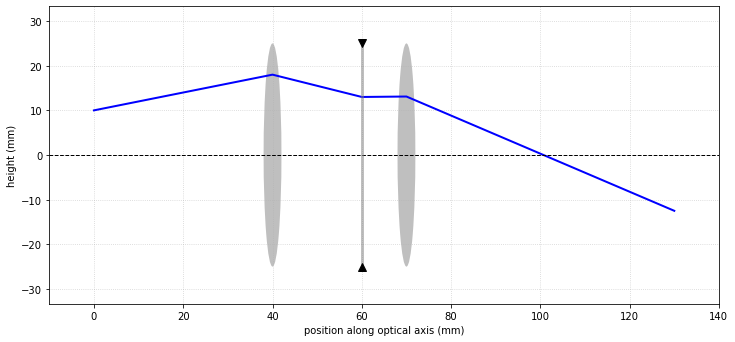

In [7]:
initial_height = 0
initial_theta = 0.2
x_ray, y_ray = calculate_ray_path(10,initial_theta)
    
fig, ax = plt.subplots(figsize=(12, 6))

# Plot the ray
ax.plot(x_ray, y_ray, 'b-', linewidth=2, label=f'Ray (θ = {initial_theta:.2f} rad)')

# Plot the optical axis
total_length = d1 + d2 + d3 + d4
ax.axhline(0, color='black', linestyle='--', linewidth=1, label='Optical Axis')

# Draw the lenses
draw_lenses_matplotlib(ax)

# Formatting
ax.set_xlabel('position along optical axis (mm)')
ax.set_ylabel('height (mm)')
ax.set_xlim(-10, total_length + 10)
ax.set_ylim(-lens_height/1.5, lens_height/1.5)
ax.set_aspect('equal', 'box')
ax.grid(True, linestyle=':', alpha=0.6)

plt.show()

## Plot with `matplotlib` and `ipywidgets` for animation

In [ ]:
%matplotlib widget
from IPython.display import display
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.path as mpath
import ipywidgets as widgets
import numpy as np

# --- 1. System Constants ---
d1, d2, d3, d4 = 40, 20, 10, 60
total_length = d1 + d2 + d3 + d4
f1, f2, f3 = 40, -50, 30

# Dimensions
LENS_H = 100
THICKNESS = 5
Y_LIMIT = 80 

# --- 2. Physics Engine ---
def get_ray_coords(y_start, theta_deg):
    theta = np.deg2rad(theta_deg)
    vec = np.array([y_start, theta])
    xs, ys = [0], [vec[0]]
    cur_x = 0
    
    def move(dist):
        nonlocal cur_x
        vec[0] += dist * vec[1]
        cur_x += dist
        xs.append(cur_x)
        ys.append(vec[0])
        
    def lens(f):
        vec[1] -= vec[0] / f
        
    move(d1); lens(f1)
    move(d2); lens(f2)
    move(d3); lens(f3)
    move(d4)
    return xs, ys

# --- 3. Build Figure ---
plt.close('all')

# We turn off interactive mode briefly so we can manually arrange the layout
plt.ioff() 

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
fig.canvas.header_visible = False
fig.canvas.footer_visible = False

# Optical Axis
ax.axhline(0, color='black', ls='--', lw=1, alpha=0.5)

# --- Draw Lenses ---
half_h = LENS_H / 2

# L1
ax.add_patch(patches.Ellipse((d1, 0), THICKNESS*2, LENS_H, fc='lightgray', ec='gray'))
ax.text(d1, -half_h - 8, "L1", ha='center')

# L2 (Concave)
verts = [
    (d1+d2 - 3,  half_h), (d1+d2, 0), (d1+d2 - 3, -half_h), 
    (d1+d2 + 3, -half_h), (d1+d2, 0), (d1+d2 + 3,  half_h), 
    (d1+d2 - 3,  half_h)
]
codes = [1, 3, 3, 2, 3, 3, 79] 
path = mpath.Path(verts, codes)
ax.add_patch(patches.PathPatch(path, fc='lightgray', ec='gray'))
ax.text(d1+d2, -half_h - 8, "L2", ha='center')

# L3
ax.add_patch(patches.Ellipse((d1+d2+d3, 0), THICKNESS*2, LENS_H, fc='lightgray', ec='gray'))
ax.text(d1+d2+d3, -half_h - 8, "L3", ha='center')

# --- 4. Dynamic Elements ---
ray_line, = ax.plot([], [], 'b-', lw=2.5)

ax.set_xlim(-10, total_length + 10)
ax.set_ylim(-Y_LIMIT, Y_LIMIT)
# ax.set_aspect('equal')
ax.set_title("Ray Tracing System")
ax.set_xlabel("Distance (mm)")
ax.set_ylabel("Height (mm)")
ax.grid(True, alpha=0.2)

# --- 5. Logic ---
def update_view(height, angle):
    xs, ys = get_ray_coords(height, angle)
    ray_line.set_data(xs, ys)
    ax.set_title(f"Ray Trace: Height={height:.1f}mm, Angle={angle:.1f}°")
    fig.canvas.draw_idle()

# --- 6. Sliders on Top ---
s_height = widgets.FloatSlider(value=10, min=-40, max=40, step=1, description='Height')
s_angle = widgets.FloatSlider(value=5, min=-20, max=20, step=0.5, description='Angle')

def on_change(change):
    update_view(s_height.value, s_angle.value)

s_height.observe(on_change, names='value')
s_angle.observe(on_change, names='value')

update_view(10, 5)

# Layout: Controls on TOP, Figure on BOTTOM
controls = widgets.HBox([s_height, s_angle])
layout = widgets.VBox([controls, fig.canvas])

# Re-enable interaction and display the layout
plt.ion()
display(layout)

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch03/ch03-03_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch03/ch03-03.html) (direct link: [ch03-03_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch03/ch03-03_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.